UPI Transaction Analytics - Exploring Payment Behavior, Transaction Reliability and Fraud Patterns in India.

Subject: Data Exploration and Visualization Laboratory

Submitted by:
1. Swaraj Suresh Shinde (125B1D053)
2. Nikol Dharmraj Ghodke (125B1D062)

## 1. Dataset and Problem Statement

**Dataset:** UPI Transactions 2024

**Source:** [Kaggle Dataset](https://www.kaggle.com/datasets/skullagos5246/upi-transactions-2024-dataset)

**Description:** The dataset contains 250,000 simulated UPI transactions with details such as transaction amount, type, status, bank, state, device, network and fraud flag.

**Problem Statement:** To analyze UPI transaction patterns and identify trends in payment behavior, transaction failures and fraud across different banks, states, devices and transaction types.

**Objectives:**
- Analyze transaction amounts and categories.
- Study transaction activity over time.
- Examine transaction failure patterns.
- Explore fraud-related patterns.
- Present findings through visualizations and an interactive dashboard.

**Key Questions:**
1. Which transaction types are most common?
2. Which merchant categories have the most transactions?
3. How are transaction amounts distributed?
4. When is transaction activity highest?
5. Which banks have the highest failure percentages?
6. How do failures vary by device and network?
7. Which states have the most fraud-flagged transactions?
8. How does fraud vary across transaction types?
9. Is transaction amount associated with fraud flags?
10. What relationships exist between numerical variables?

Part 2: Data Exploration and Preprocessing

Importing necessary libraries for EDA

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("upi_transactions_2024.csv")

Understanding the dataset using shape, head, tail, info

In [4]:
df.shape

(250000, 17)

In [5]:
df.head()

,transaction id,timestamp,transaction type,merchant_category,amount (INR),transaction_status,sender_age_group,receiver_age_group,sender_state,sender_bank,receiver_bank,device_type,network_type,fraud_flag,hour_of_day,day_of_week,is_weekend
0,TXN0000000001,2024-10-08 15:17:28,P2P,Entertainment,868,SUCCESS,26-35,18-25,Delhi,Axis,SBI,Android,4G,0,15,Tuesday,0
1,TXN0000000002,2024-04-11 06:56:00,P2M,Grocery,1011,SUCCESS,26-35,26-35,Uttar Pradesh,ICICI,Axis,iOS,4G,0,6,Thursday,0
2,TXN0000000003,2024-04-02 13:27:18,P2P,Grocery,477,SUCCESS,26-35,36-45,Karnataka,Yes Bank,PNB,Android,4G,0,13,Tuesday,0
3,TXN0000000004,2024-01-07 10:09:17,P2P,Fuel,2784,SUCCESS,26-35,26-35,Delhi,ICICI,PNB,Android,5G,0,10,Sunday,1
4,TXN0000000005,2024-01-23 19:04:23,P2P,Shopping,990,SUCCESS,26-35,18-25,Delhi,Axis,Yes Bank,iOS,WiFi,0,19,Tuesday,0


In [6]:
df.tail()

,transaction id,timestamp,transaction type,merchant_category,amount (INR),transaction_status,sender_age_group,receiver_age_group,sender_state,sender_bank,receiver_bank,device_type,network_type,fraud_flag,hour_of_day,day_of_week,is_weekend
249995,TXN0000249996,2024-11-08 22:41:43,Recharge,Food,373,SUCCESS,36-45,26-35,Telangana,ICICI,HDFC,iOS,5G,0,22,Friday,0
249996,TXN0000249997,2024-12-15 02:58:03,P2P,Utilities,2025,SUCCESS,36-45,26-35,Rajasthan,HDFC,Yes Bank,Android,5G,0,2,Sunday,1
249997,TXN0000249998,2024-11-27 16:33:25,P2P,Food,468,SUCCESS,26-35,18-25,West Bengal,ICICI,ICICI,Android,4G,0,16,Wednesday,0
249998,TXN0000249999,2024-01-05 13:31:30,Recharge,Healthcare,284,SUCCESS,18-25,36-45,Andhra Pradesh,Axis,ICICI,iOS,4G,0,13,Friday,0
249999,TXN0000250000,2024-01-17 15:23:07,P2P,Entertainment,531,SUCCESS,18-25,26-35,Telangana,Axis,Yes Bank,Android,4G,0,15,Wednesday,0


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 17 columns):
 #   Column              Non-Null Count   Dtype
---  ------              --------------   -----
 0   transaction id      250000 non-null  str  
 1   timestamp           250000 non-null  str  
 2   transaction type    250000 non-null  str  
 3   merchant_category   250000 non-null  str  
 4   amount (INR)        250000 non-null  int64
 5   transaction_status  250000 non-null  str  
 6   sender_age_group    250000 non-null  str  
 7   receiver_age_group  250000 non-null  str  
 8   sender_state        250000 non-null  str  
 9   sender_bank         250000 non-null  str  
 10  receiver_bank       250000 non-null  str  
 11  device_type         250000 non-null  str  
 12  network_type        250000 non-null  str  
 13  fraud_flag          250000 non-null  int64
 14  hour_of_day         250000 non-null  int64
 15  day_of_week         250000 non-null  str  
 16  is_weekend          250000 non-

Statistical summary using describe()

In [8]:
df.describe(include="all")

,transaction id,timestamp,transaction type,merchant_category,amount (INR),transaction_status,sender_age_group,receiver_age_group,sender_state,sender_bank,receiver_bank,device_type,network_type,fraud_flag,hour_of_day,day_of_week,is_weekend
count,250000,250000,250000,250000,250000.000000,250000,250000,250000,250000,250000,250000,250000,250000,250000.000000,250000.000000,250000,250000.000000
unique,250000,248610,4,10,NaN,2,5,5,10,8,8,3,4,NaN,NaN,7,NaN
top,TXN0000000001,2024-09-19 12:40:40,P2P,Grocery,NaN,SUCCESS,26-35,26-35,Maharashtra,SBI,SBI,Android,4G,NaN,NaN,Monday,NaN
freq,1,3,112445,49966,NaN,237624,87432,87864,37427,62693,62378,187777,149813,NaN,NaN,36495,NaN
mean,NaN,NaN,NaN,NaN,1311.756036,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.001920,14.681032,NaN,0.285348
std,NaN,NaN,NaN,NaN,1848.059224,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.043776,5.188304,NaN,0.451581
min,NaN,NaN,NaN,NaN,10.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,NaN,0.000000
25%,NaN,NaN,NaN,NaN,288.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,11.000000,NaN,0.000000
50%,NaN,NaN,NaN,NaN,629.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,15.000000,NaN,0.000000
75%,NaN,NaN,NaN,NaN,1596.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,19.000000,NaN,1.000000


Checking null values

In [9]:
df.isnull().sum()

transaction id        0
timestamp             0
transaction type      0
merchant_category     0
amount (INR)          0
transaction_status    0
sender_age_group      0
receiver_age_group    0
sender_state          0
sender_bank           0
receiver_bank         0
device_type           0
network_type          0
fraud_flag            0
hour_of_day           0
day_of_week           0
is_weekend            0
dtype: int64

Checking data types of columns 

In [10]:
df.dtypes

transaction id          str
timestamp               str
transaction type        str
merchant_category       str
amount (INR)          int64
transaction_status      str
sender_age_group        str
receiver_age_group      str
sender_state            str
sender_bank             str
receiver_bank           str
device_type             str
network_type            str
fraud_flag            int64
hour_of_day           int64
day_of_week             str
is_weekend            int64
dtype: object

In [11]:
df.isna().sum()

transaction id        0
timestamp             0
transaction type      0
merchant_category     0
amount (INR)          0
transaction_status    0
sender_age_group      0
receiver_age_group    0
sender_state          0
sender_bank           0
receiver_bank         0
device_type           0
network_type          0
fraud_flag            0
hour_of_day           0
day_of_week           0
is_weekend            0
dtype: int64

Checking unique values in each column

In [12]:
df.nunique()

transaction id        250000
timestamp             248610
transaction type           4
merchant_category         10
amount (INR)           10355
transaction_status         2
sender_age_group           5
receiver_age_group         5
sender_state              10
sender_bank                8
receiver_bank              8
device_type                3
network_type               4
fraud_flag                 2
hour_of_day               24
day_of_week                7
is_weekend                 2
dtype: int64

In [13]:
df.duplicated().sum()

np.int64(0)

Drop columns that are not useful like transaction id

In [14]:
df1 = df.drop(columns=['transaction id'])
df1

,timestamp,transaction type,merchant_category,amount (INR),transaction_status,sender_age_group,receiver_age_group,sender_state,sender_bank,receiver_bank,device_type,network_type,fraud_flag,hour_of_day,day_of_week,is_weekend
0,2024-10-08 15:17:28,P2P,Entertainment,868,SUCCESS,26-35,18-25,Delhi,Axis,SBI,Android,4G,0,15,Tuesday,0
1,2024-04-11 06:56:00,P2M,Grocery,1011,SUCCESS,26-35,26-35,Uttar Pradesh,ICICI,Axis,iOS,4G,0,6,Thursday,0
2,2024-04-02 13:27:18,P2P,Grocery,477,SUCCESS,26-35,36-45,Karnataka,Yes Bank,PNB,Android,4G,0,13,Tuesday,0
3,2024-01-07 10:09:17,P2P,Fuel,2784,SUCCESS,26-35,26-35,Delhi,ICICI,PNB,Android,5G,0,10,Sunday,1
4,2024-01-23 19:04:23,P2P,Shopping,990,SUCCESS,26-35,18-25,Delhi,Axis,Yes Bank,iOS,WiFi,0,19,Tuesday,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
249995,2024-11-08 22:41:43,Recharge,Food,373,SUCCESS,36-45,26-35,Telangana,ICICI,HDFC,iOS,5G,0,22,Friday,0
249996,2024-12-15 02:58:03,P2P,Utilities,2025,SUCCESS,36-45,26-35,Rajasthan,HDFC,Yes Bank,Android,5G,0,2,Sunday,1
249997,2024-11-27 16:33:25,P2P,Food,468,SUCCESS,26-35,18-25,West Bengal,ICICI,ICICI,Android,4G,0,16,Wednesday,0
249998,2024-01-05 13:31:30,Recharge,Healthcare,284,SUCCESS,18-25,36-45,Andhra Pradesh,Axis,ICICI,iOS,4G,0,13,Friday,0


In [15]:
df1.shape

(250000, 16)

Converted date and time to different data types

In [16]:
df1["timestamp"] = pd.to_datetime(df["timestamp"])
df1.dtypes

timestamp             datetime64[us]
transaction type                 str
merchant_category                str
amount (INR)                   int64
transaction_status               str
sender_age_group                 str
receiver_age_group               str
sender_state                     str
sender_bank                      str
receiver_bank                    str
device_type                      str
network_type                     str
fraud_flag                     int64
hour_of_day                    int64
day_of_week                      str
is_weekend                     int64
dtype: object

Statistical summary of amount column

In [17]:
df1["amount (INR)"].describe()

count    250000.000000
mean       1311.756036
std        1848.059224
min          10.000000
25%         288.000000
50%         629.000000
75%        1596.000000
max       42099.000000
Name: amount (INR), dtype: float64

Count of different types of transactions

In [18]:
df1["transaction type"].value_counts()

transaction type
P2P             112445
P2M              87660
Bill Payment     37368
Recharge         12527
Name: count, dtype: int64

Count of failed transactions

In [19]:
df1["transaction_status"].value_counts()

transaction_status
SUCCESS    237624
FAILED      12376
Name: count, dtype: int64

calculating % of transactions failed

In [20]:
print("% of transactions failed: ",(12376/250000)*100)

% of transactions failed:  4.9504


Finding different types of categories in which transaction is made 

In [21]:
df["merchant_category"].value_counts()

merchant_category
Grocery          49966
Food             37464
Shopping         29872
Fuel             25063
Other            24828
Utilities        22338
Transport        20105
Entertainment    20103
Healthcare       12663
Education         7598
Name: count, dtype: int64

Part 3: Exploratory Data Analysis

Univariate

Frequency of each transaction type

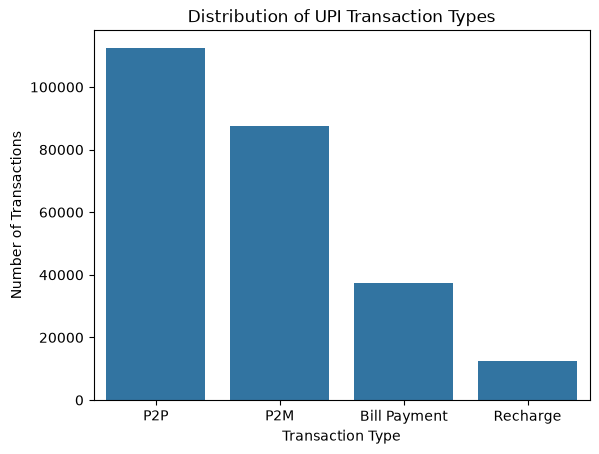

In [22]:
sns.countplot(data=df1, x="transaction type")

plt.title("Distribution of UPI Transaction Types")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")
plt.show()

Frequency of failed vs successfull transactions

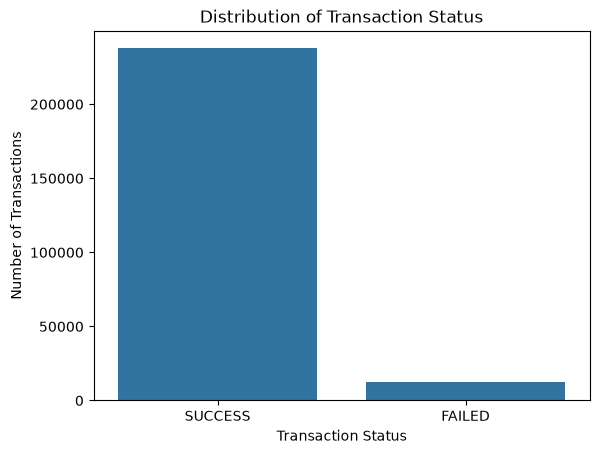

In [23]:
sns.countplot(data=df1, x="transaction_status")

plt.title("Distribution of Transaction Status")
plt.xlabel("Transaction Status")
plt.ylabel("Number of Transactions")
plt.show()

Bivariate

Transaction type and amount of transaction are taken as two variables

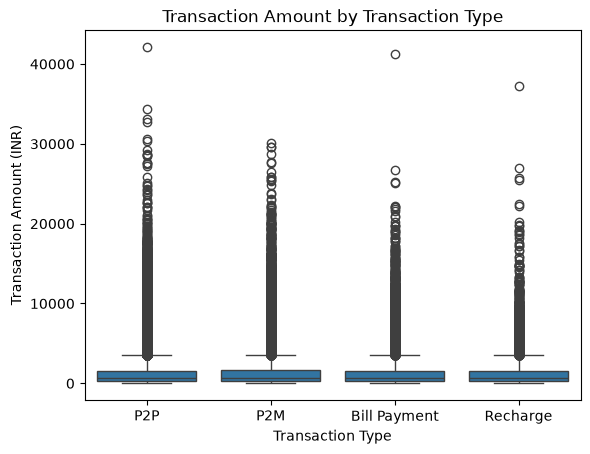

In [24]:
sns.boxplot(data=df, x="transaction type", y="amount (INR)")

plt.title("Transaction Amount by Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Transaction Amount (INR)")
plt.show()

Category wise successfull vs failed transactions

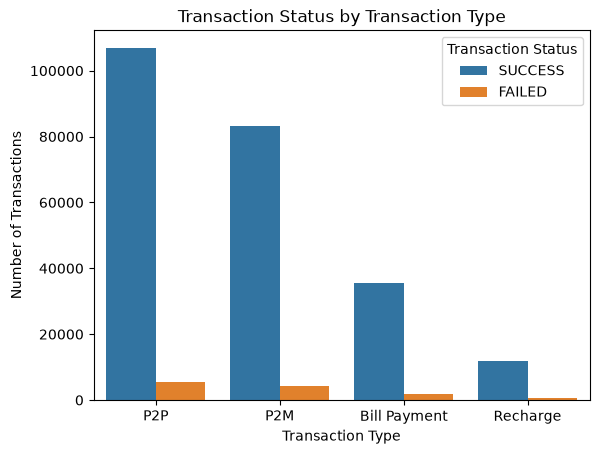

In [25]:
sns.countplot(
    data=df,
    x="transaction type",
    hue="transaction_status"
)

plt.title("Transaction Status by Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")
plt.legend(title="Transaction Status")
plt.show()

No. of transactions per merchant category

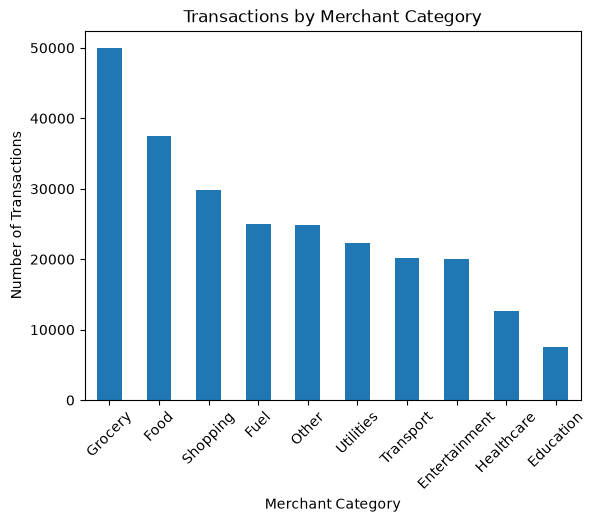

In [26]:
merchant_counts = df["merchant_category"].value_counts()

merchant_counts.plot(kind="bar")

plt.title("Transactions by Merchant Category")
plt.xlabel("Merchant Category")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45)
plt.show()

No. of transactions per hour of the day

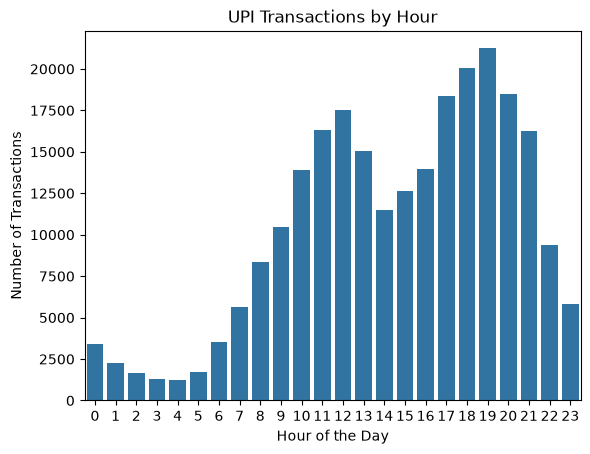

In [27]:
sns.countplot(data=df, x="hour_of_day")

plt.title("UPI Transactions by Hour")
plt.xlabel("Hour of the Day")
plt.ylabel("Number of Transactions")
plt.show()

No. of transactions per day of the week

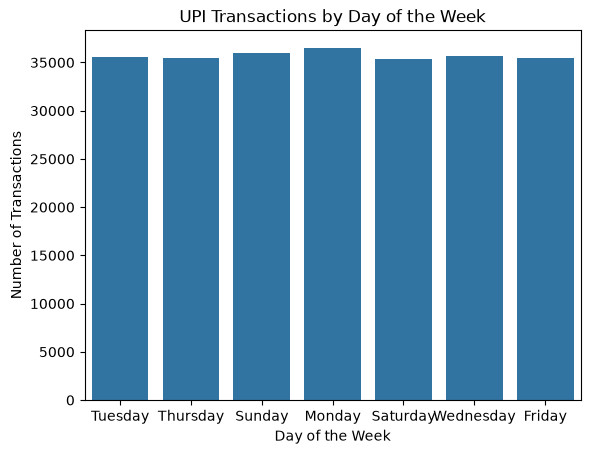

In [28]:
sns.countplot(data=df, x="day_of_week")

plt.title("UPI Transactions by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Number of Transactions")
plt.show()

Weekday vs Weekend comparison

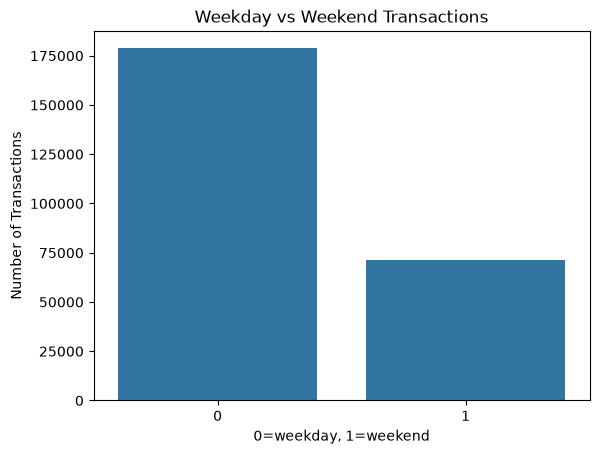

In [29]:
sns.countplot(data=df, x="is_weekend")

plt.title("Weekday vs Weekend Transactions")
plt.xlabel("0=weekday, 1=weekend")
plt.ylabel("Number of Transactions")
plt.show()

In [30]:
bank_count = df["sender_bank"].value_counts()
bank_count

sender_bank
SBI         62693
HDFC        37485
ICICI       29769
IndusInd    25173
Axis        25042
PNB         24946
Yes Bank    24860
Kotak       20032
Name: count, dtype: int64

Top Banks according to no. of transactions

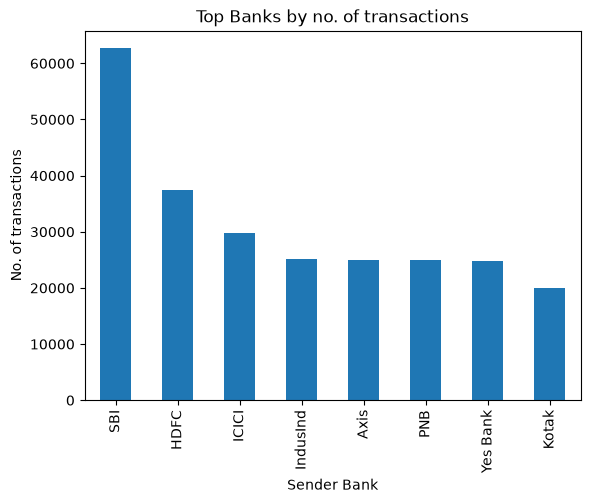

In [31]:
bank_count.plot(kind="bar")
plt.title("Top Banks by no. of transactions")
plt.xlabel("Sender Bank")
plt.ylabel("No. of transactions")
plt.show()

Top banks according to failed transactions

In [32]:
failed_transactions = df[df["transaction_status"]=="FAILED"]
failed_bank_count = failed_transactions["sender_bank"].value_counts()
failed_bank_count

sender_bank
SBI         3095
HDFC        1808
ICICI       1499
Yes Bank    1269
IndusInd    1247
Axis        1239
PNB         1221
Kotak        998
Name: count, dtype: int64

% of transactions that failed

In [33]:
failed_percentage = (failed_bank_count / bank_count) * 100
failed_percentage

sender_bank
Axis        4.947688
HDFC        4.823263
ICICI       5.035440
IndusInd    4.953720
Kotak       4.982029
PNB         4.894572
SBI         4.936755
Yes Bank    5.104586
Name: count, dtype: float64

Transactions per state

In [34]:
state_counts = df["sender_state"].value_counts()
state_counts

sender_state
Maharashtra       37427
Uttar Pradesh     30125
Karnataka         29756
Tamil Nadu        25367
Delhi             24870
Telangana         22435
Gujarat           20061
Andhra Pradesh    20006
Rajasthan         19981
West Bengal       19972
Name: count, dtype: int64

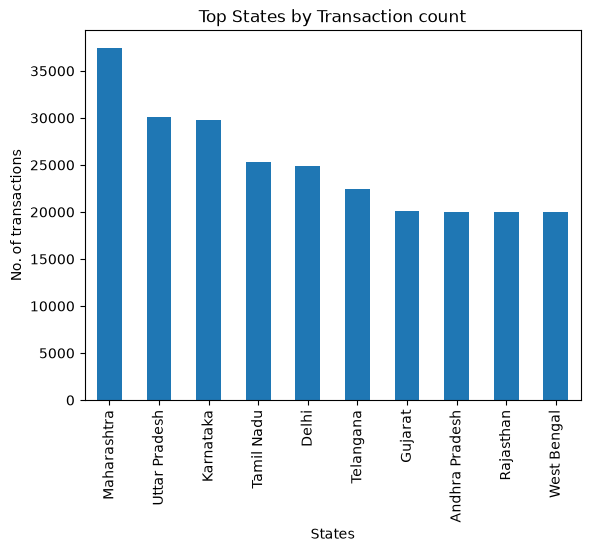

In [35]:
state_counts.plot(kind="bar")
plt.title("Top States by Transaction count")
plt.xlabel("States")
plt.ylabel("No. of transactions")
plt.show()

Average transaction amount per category

In [36]:
average_amount = df.groupby("transaction type")["amount (INR)"].mean()
average_amount

transaction type
Bill Payment    1308.492373
P2M             1320.072633
P2P             1308.681115
Recharge        1290.895745
Name: amount (INR), dtype: float64

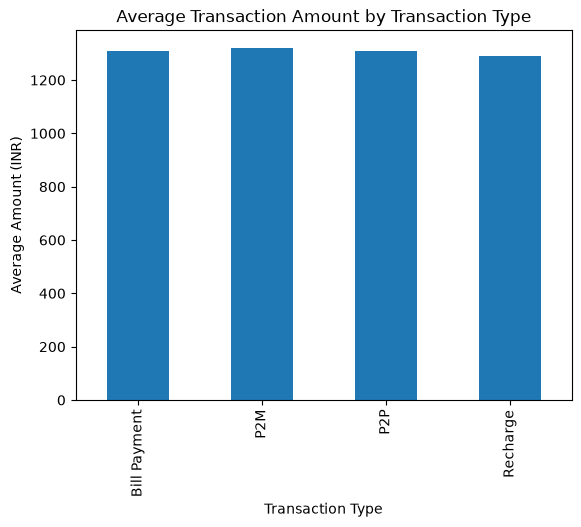

In [37]:
average_amount.plot(kind="bar")

plt.title("Average Transaction Amount by Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Average Amount (INR)")
plt.show()

In [38]:
fraud_transactions = df[df["fraud_flag"] == 1]

fraud_type_count = fraud_transactions["transaction type"].value_counts()

total_type_count = df["transaction type"].value_counts()

fraud_type_percentage = (fraud_type_count / total_type_count) * 100
fraud_type_percentage

transaction type
P2P             0.183201
P2M             0.190509
Bill Payment    0.206059
Recharge        0.239483
Name: count, dtype: float64

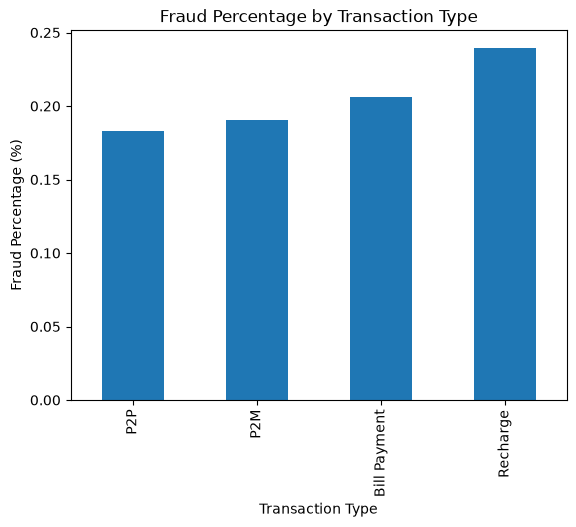

In [39]:
fraud_type_percentage.sort_values().plot(kind="bar")

plt.title("Fraud Percentage by Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Fraud Percentage (%)")
plt.show()

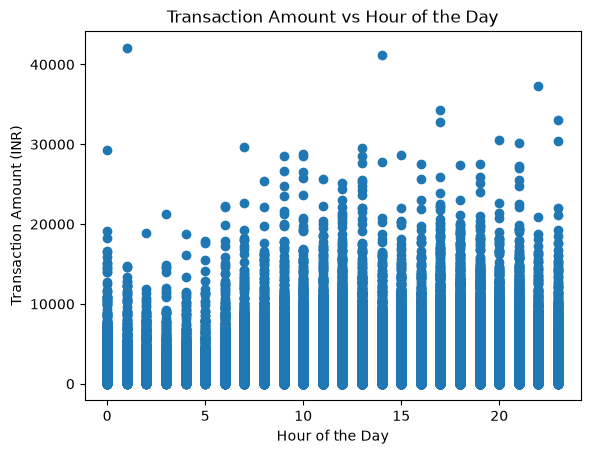

In [40]:
plt.scatter(df["hour_of_day"], df["amount (INR)"])

plt.title("Transaction Amount vs Hour of the Day")
plt.xlabel("Hour of the Day")
plt.ylabel("Transaction Amount (INR)")
plt.show()

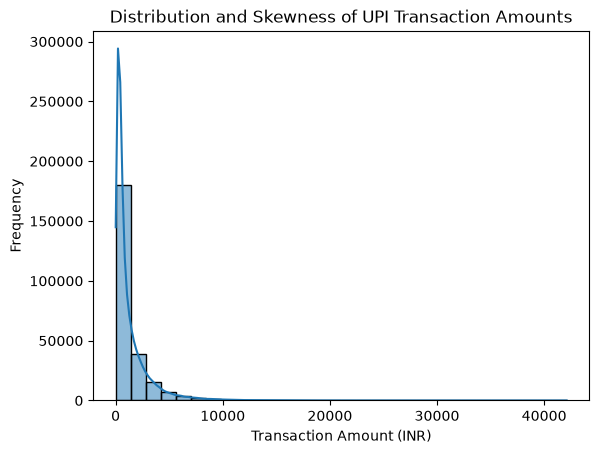

In [41]:
sns.histplot(df["amount (INR)"], bins=30, kde=True)

plt.title("Distribution and Skewness of UPI Transaction Amounts")
plt.xlabel("Transaction Amount (INR)")
plt.ylabel("Frequency")
plt.show()

              amount (INR)  hour_of_day  is_weekend  fraud_flag
amount (INR)      1.000000    -0.001604   -0.000653    0.004449
hour_of_day      -0.001604     1.000000    0.001496    0.001323
is_weekend       -0.000653     0.001496    1.000000    0.001221
fraud_flag        0.004449     0.001323    0.001221    1.000000


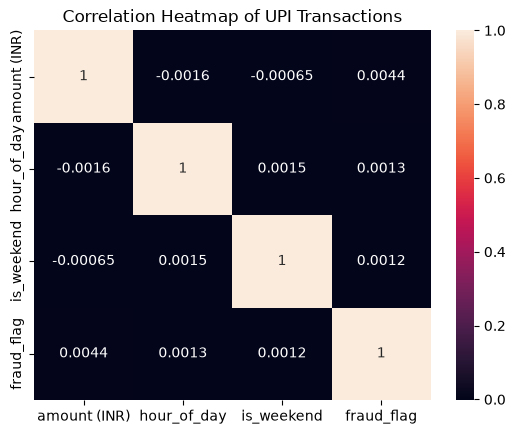

In [42]:
data = df[["amount (INR)", "hour_of_day", "is_weekend", "fraud_flag"]]

# Calculate correlation
correlation = data.corr()

# Display correlation values
print(correlation)

# Plot correlation heatmap
sns.heatmap(correlation, annot=True)

plt.title("Correlation Heatmap of UPI Transactions")
plt.show()

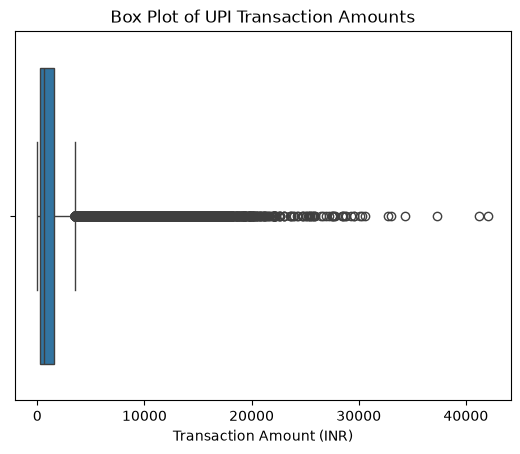

In [43]:
sns.boxplot(x=df["amount (INR)"])

plt.title("Box Plot of UPI Transaction Amounts")
plt.xlabel("Transaction Amount (INR)")
plt.show()

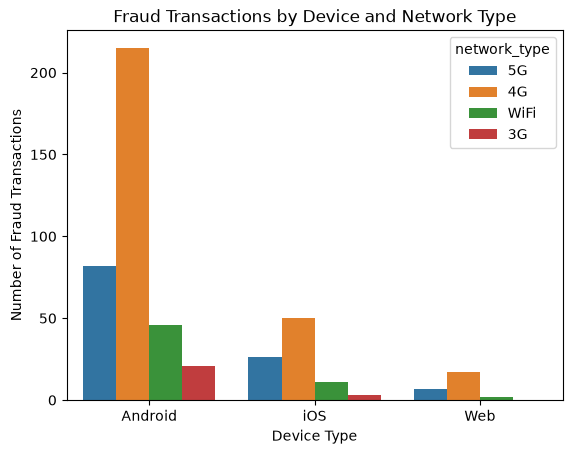

In [44]:
fraud_transactions = df[df["fraud_flag"] == 1]
device_fraud = df.groupby(["device_type","network_type"]).size()

sns.countplot(
    data=fraud_transactions,
    x="device_type",
    hue="network_type"
)

plt.title("Fraud Transactions by Device and Network Type")
plt.xlabel("Device Type")
plt.ylabel("Number of Fraud Transactions")
plt.show()

sender_state
Maharashtra       71
Karnataka         69
Uttar Pradesh     52
Delhi             50
Rajasthan         46
Gujarat           43
Tamil Nadu        40
Telangana         39
Andhra Pradesh    35
West Bengal       35
Name: count, dtype: int64


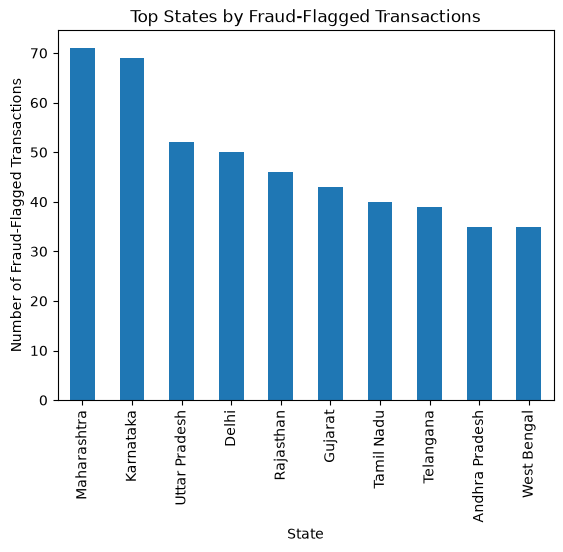

In [46]:
fraud_transactions = df[df["fraud_flag"] == 1]
fraud_state_count = fraud_transactions["sender_state"].value_counts()

print(fraud_state_count)

# Plot bar graph
fraud_state_count.plot(kind="bar")

plt.title("Top States by Fraud-Flagged Transactions")
plt.xlabel("State")
plt.ylabel("Number of Fraud-Flagged Transactions")
plt.show()